# Sentiment Signal: Static Study of News Sentiment and Abnormal Returns

**Name:** Nakul Pillai

**Project title:** News Sentiment and Abnormal Return Predictability in US Stocks

This notebook is the frozen, reproducible version of the live Sentiment Signal app. It tests whether FinBERT news sentiment predicts a stock's abnormal returns over the following days, and whether a simple long/short strategy built on it beats holding the same stocks. Every parameter was locked in `PARAMETERS.md` before any news data was downloaded.

*Run `data_pipeline.py` first (it filters the FNSPID news, picks the window and scores the headlines). This notebook then runs everything else.*

## 0. Imports and Setup

Importing libraries and setting up the fixed parameters. These mirror `PARAMETERS.md` and are not tuned afterwards.

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

BETA_WINDOW = 120            # trading days used to estimate each stock's beta (ending the day before the event)
MARKET_CLOSE_HOUR = 16       # articles at/after 16:00 New York time count for the next trading day
EXCHANGE_TZ = "America/New_York"
DATE_ONLY_SHARE = 0.99       # if >=99% of timestamps are midnight the file only has dates
EVENT_DAYS = (0, 1, 2, 3, 4) # days after the event day that are examined
STRATEGY = "immediate"       # "immediate" = Strategy B (buy the close of the news day, hold 1 day); "delayed" = Strategy A (first design)
TRADE_DAYS = (1,) if STRATEGY == "immediate" else (2, 3, 4)   # days after the event day that the trade earns
SAME_DAY_FOR_DATES = STRATEGY == "immediate"   # date-only files: the article's own date is the event day
THRESHOLD = 0.5              # |average stock-day sentiment| >= 0.5 triggers a trade
MIN_ARTICLES = 1
COST_BPS = 10                # round-trip trading cost (10 bps = 0.10%)
THRESHOLD_SENSITIVITY = (0.3, 0.7)
TRADING_DAYS = 252

results = {}                 # everything the report quotes ends up here
timings = {}

## 1. Data Loading

This loads the 50-stock price file and the S&P 500, the study window, and the scored news produced by `data_pipeline.py`.

In [2]:
prices = pd.read_csv(DATA_DIR / "adj_close_clean.csv", index_col=0, parse_dates=True).sort_index()
prices.index = pd.DatetimeIndex(prices.index).normalize()
sp500 = pd.read_csv(DATA_DIR / "sp500.csv", index_col=0, parse_dates=True).iloc[:, 0].sort_index()
sp500.index = pd.DatetimeIndex(sp500.index).normalize()
sp500 = sp500.reindex(prices.index)

window = {k: pd.Timestamp(v) for k, v in json.load(open(DATA_DIR / "window.json")).items()}
news = pd.read_csv(DATA_DIR / "news_scored.csv.gz")
news["ts_utc"] = pd.to_datetime(news["ts_utc"], utc=True)
calendar, tickers = prices.index, list(prices.columns)

print(f"Prices: {prices.shape[1]} stocks, {calendar[0].date()} to {calendar[-1].date()}")
print(f"Window: {window['start'].date()} to {window['end'].date()} "
      f"(in-sample to {window['in_sample_end'].date()}, out-of-sample from {window['holdout_start'].date()})")
print(f"Scored articles: {len(news):,} across {news['ticker'].nunique()} tickers")
results["window"] = {k: str(v.date()) for k, v in window.items()}
results["articles_loaded"] = int(len(news))

Prices: 50 stocks, 2020-05-01 to 2024-02-28
Window: 2021-01-01 to 2023-12-31 (in-sample to 2022-12-31, out-of-sample from 2023-01-01)
Scored articles: 28,078 across 50 tickers


## 2. Data Cleaning and Alignment

This turns each article's timestamp into the trading day it could first affect, then averages the scores for each stock on each day. An article published before 16:00 New York time on a trading day belongs to that day. After 16:00, or on a weekend or holiday, it belongs to the next trading day. If the file only has dates, Strategy B (the one reported) puts every article on its own date, or the next trading day if that date is a weekend or holiday, and the trade starts at that day's close. Because the time of day is unknown, some articles dated D were published after the close of D, and for those the entry at the close of D is slightly too early to be tradeable. This favours the strategy and is disclosed in the report. Strategy A (the first design) put date-only articles on the next trading day.

In [3]:
def assign_event_days(news, cal):
    """Map each article to its event day (a position in the trading calendar `cal`)."""
    ts = pd.to_datetime(news["ts_utc"], utc=True)
    midnight = ((ts.dt.hour == 0) & (ts.dt.minute == 0) & (ts.dt.second == 0)).mean()
    date_only = bool(midnight >= DATE_ONLY_SHARE)
    if date_only:
        local_date = ts.dt.tz_localize(None).dt.normalize()
        before_close = pd.Series(SAME_DAY_FOR_DATES, index=ts.index)
    else:
        local = ts.dt.tz_convert(EXCHANGE_TZ)
        local_date = local.dt.tz_localize(None).dt.normalize()
        before_close = (local.dt.hour + local.dt.minute / 60) < MARKET_CLOSE_HOUR

    cal_v = cal.values.astype("datetime64[D]")
    d = local_date.values.astype("datetime64[D]")
    left = np.searchsorted(cal_v, d, side="left")      # first trading day on/after the date
    right = np.searchsorted(cal_v, d, side="right")    # first trading day strictly after the date
    on_day = (left < len(cal_v)) & (cal_v[np.minimum(left, len(cal_v) - 1)] == d)
    idx = np.where(before_close.values & on_day, left, right)
    out = news.copy()
    out["event_idx"] = idx
    out = out[out["event_idx"] < len(cal_v)]
    out.attrs["date_only"] = date_only
    return out


def stock_day_scores(news, tickers, cols=("finbert", "vader")):
    """One row per (stock, event day): average score and number of articles."""
    g = news.groupby(["ticker", "event_idx"])
    ev = g[list(cols)].mean()
    ev["n_articles"] = g.size()
    ev = ev.reset_index()
    ev["col"] = ev["ticker"].map({t: i for i, t in enumerate(tickers)})
    return ev.dropna(subset=["col"]).astype({"col": int})


t0 = time.perf_counter()
news = assign_event_days(news, calendar)
events = stock_day_scores(news, tickers)
timings["align_and_aggregate"] = time.perf_counter() - t0

print("Timestamps are date-only:", news.attrs["date_only"])
print(f"{len(news):,} articles -> {len(events):,} stock-days with news")
results["date_only_timestamps"] = news.attrs["date_only"]

Timestamps are date-only: True
28,078 articles -> 15,593 stock-days with news


## 3. Abnormal Returns

A stock's raw daily return is mostly the market moving. This subtracts each stock's expected move given the S&P 500 (a market-model beta estimated on the 120 trading days up to the day before the event) to leave the part that belongs to the stock itself, called its abnormal return. It is measured in basis points on the event day (day 0) and the four days after.

In [4]:
def returns_and_betas(px, mk):
    """Daily returns, market returns, and each stock's trailing beta (window ends the day BEFORE each date)."""
    R = px.pct_change()
    M = mk.pct_change()
    var = M.rolling(BETA_WINDOW).var()
    B = R.apply(lambda s: s.rolling(BETA_WINDOW).cov(M)).div(var, axis=0).shift(1)
    return R, M, B


def add_abnormal_returns(ev, R, M, B):
    Rv, Mv, Bv = R.values, M.values, B.values
    T = Rv.shape[0]
    t, j = ev["event_idx"].to_numpy(), ev["col"].to_numpy()
    ev = ev.copy()
    for k in EVENT_DAYS:
        ok = t + k < T
        a = np.full(len(ev), np.nan)
        a[ok] = Rv[t[ok] + k, j[ok]] - Bv[t[ok], j[ok]] * Mv[t[ok] + k]
        ev[f"ar{k}"] = a * 1e4                                       # basis points
    ev["car_trade"] = ev[[f"ar{k}" for k in TRADE_DAYS]].sum(axis=1, skipna=False)   # the days the strategy earns
    ev["car24"] = ev[["ar2", "ar3", "ar4"]].sum(axis=1, skipna=False)
    return ev


def label_periods(ev, cal, win):
    d = cal[ev["event_idx"].to_numpy()]
    lab = np.full(len(ev), "outside", dtype=object)
    lab[(d >= win["start"]) & (d <= win["in_sample_end"])] = "in_sample"
    lab[(d >= win["holdout_start"]) & (d <= win["end"])] = "out_of_sample"
    ev = ev.copy()
    ev["period"] = lab
    return ev


t0 = time.perf_counter()
returns, mkt_returns, betas = returns_and_betas(prices, sp500)
events = add_abnormal_returns(events, returns, mkt_returns, betas)
events = label_periods(events, calendar, window)
timings["abnormal_returns"] = time.perf_counter() - t0

news["period"] = label_periods(news, calendar, window)["period"].to_numpy()
inwin = events[events["period"] != "outside"]
print(inwin["period"].value_counts().to_string())
print(f"Median beta used: {np.nanmedian(betas.values):.2f}")

period
in_sample        9812
out_of_sample    5780
Median beta used: 0.98


## 4. Sentiment Descriptives

This looks at what the scores actually look like and how much the two models agree, before any return is involved.

articles_in_window: 28072
stock_days: 15592
tickers_with_news: 50
tickers_total: 50
median_articles_per_stock_day: 1.0
finbert_vader_corr: 0.37606722291891187
sign_agreement_nonneutral: 0.7115243454856863
share_stock_days_above_threshold: 0.18227296049256028


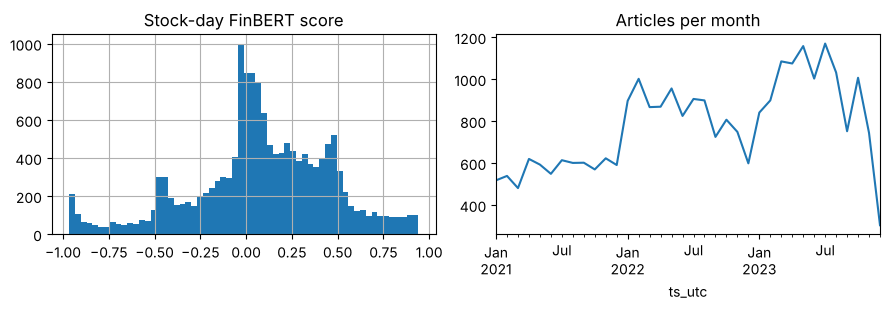

In [5]:
agree_mask = (inwin["finbert"].abs() > 0.05) & (inwin["vader"].abs() > 0.05)
results["data"] = {
    "articles_in_window": int((news["period"] != "outside").sum()),
    "articles_by_period": news["period"].value_counts().to_dict(),
    "stock_days": int(len(inwin)),
    "stock_days_by_period": inwin["period"].value_counts().to_dict(),
    "tickers_with_news": int(inwin["ticker"].nunique()),
    "tickers_total": len(tickers),
    "median_articles_per_stock_day": float(inwin["n_articles"].median()),
    "finbert_describe": inwin["finbert"].describe().round(4).to_dict(),
    "vader_describe": inwin["vader"].describe().round(4).to_dict(),
    "finbert_vader_corr": float(inwin["finbert"].corr(inwin["vader"])),
    "sign_agreement_nonneutral": float((np.sign(inwin["finbert"]) == np.sign(inwin["vader"]))[agree_mask].mean()),
    "share_stock_days_above_threshold": float((inwin["finbert"].abs() >= THRESHOLD).mean()),
}
for k, v in results["data"].items():
    if not isinstance(v, dict):
        print(f"{k}: {v}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
inwin["finbert"].hist(bins=60, ax=axes[0], color="#1f77b4")
axes[0].set_title("Stock-day FinBERT score")
m = news[news["period"] != "outside"]
m.groupby(m["ts_utc"].dt.tz_localize(None).dt.to_period("M")).size().plot(ax=axes[1], color="#1f77b4")
axes[1].set_title("Articles per month")
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_data_overview.png", dpi=150)
plt.show()

## 5. Event Study: Does Sentiment Predict Abnormal Returns?

This is the core test, and the lag check. It regresses abnormal return on the stock-day sentiment score (standard errors clustered by stock). Day 0 is the article's own day, which the strategy cannot trade (it enters at that day's close), so it is a diagnostic. Day 1 is the primary test for Strategy B, because it is the one day the strategy earns. Days 2 to 4 show whether anything is left after that.

In [6]:
def cluster_ols(df, y, x):
    d = df[[y, x, "ticker"]].dropna()
    if len(d) < 30 or d[x].std() == 0:
        return {"n": len(d), "coef": np.nan, "se": np.nan, "t": np.nan, "p": np.nan, "r2": np.nan}
    m = sm.OLS(d[y], sm.add_constant(d[x])).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(d["ticker"])[0]})
    ci = m.conf_int().loc[x]
    return {"n": int(len(d)), "coef": float(m.params[x]), "se": float(m.bse[x]), "t": float(m.tvalues[x]),
            "p": float(m.pvalues[x]), "ci_lo": float(ci[0]), "ci_hi": float(ci[1]), "r2": float(m.rsquared)}


def event_regressions(ev, score, period):
    d = ev[ev["period"] == period]
    return {y: cluster_ols(d, y, score) for y in ["ar0", "ar1", "car24", "car_trade"]}


def directional_profile(ev, score, threshold, period):
    """Average abnormal return by day, in the direction of the sentiment (bps)."""
    d = ev[(ev["period"] == period) & (ev[score].abs() >= threshold) & (ev["n_articles"] >= MIN_ARTICLES)]
    sign = np.sign(d[score])
    prof = {f"day {k}": float((d[f"ar{k}"] * sign).mean()) for k in EVENT_DAYS}
    prof["n_events"] = int(len(d))
    return prof


rows, results["event_study"], results["profile"] = [], {}, {}
for score in ("finbert", "vader"):
    for period in ("in_sample", "out_of_sample"):
        reg = event_regressions(events, score, period)
        results["event_study"][f"{score}_{period}"] = reg
        results["profile"][f"{score}_{period}"] = directional_profile(events, score, THRESHOLD, period)
        names = (("ar0", "day 0"), ("ar1", "day 1 (primary)"), ("car24", "days 2-4")) if STRATEGY == "immediate" else (("ar0", "day 0"), ("ar1", "day 1"), ("car24", "days 2-4 (primary)"))
        for y, name in names:
            r = reg[y]
            rows.append({"model": score, "period": period, "outcome": name, "n": r["n"],
                         "coef (bps per unit score)": r["coef"], "t": r["t"], "p": r["p"]})
event_table = pd.DataFrame(rows)
print(event_table.round(3).to_string(index=False))
event_table.to_csv(OUT_DIR / "table_event_study.csv", index=False)

  model        period         outcome    n  coef (bps per unit score)      t     p
finbert     in_sample           day 0 9812                    110.242  4.651 0.000
finbert     in_sample day 1 (primary) 9812                      9.748  1.032 0.302
finbert     in_sample        days 2-4 9812                    -18.407 -1.445 0.149
finbert out_of_sample           day 0 5780                     78.060  4.403 0.000
finbert out_of_sample day 1 (primary) 5780                      8.134  0.956 0.339
finbert out_of_sample        days 2-4 5780                      2.204  0.184 0.854
  vader     in_sample           day 0 9812                     47.091  3.303 0.001
  vader     in_sample day 1 (primary) 9812                      8.259  0.791 0.429
  vader     in_sample        days 2-4 9812                     -5.692 -0.219 0.827
  vader out_of_sample           day 0 5780                     29.168  1.997 0.046
  vader out_of_sample day 1 (primary) 5780                      5.914  0.410 0.682
  va

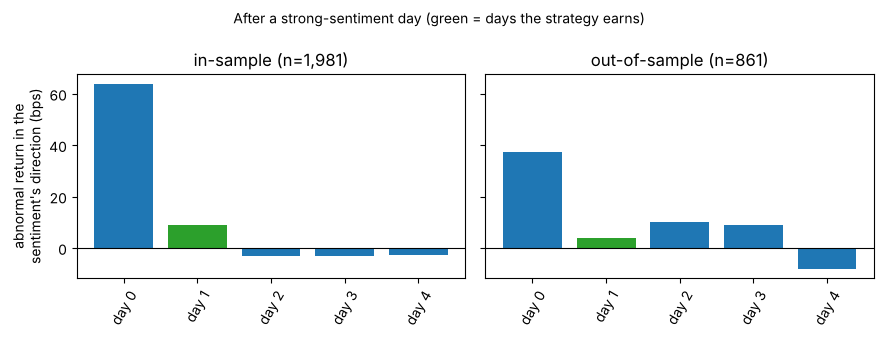

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, period in zip(axes, ("in_sample", "out_of_sample")):
    prof = results["profile"][f"finbert_{period}"]
    ax.bar([f"day {k}" for k in EVENT_DAYS], [prof[f"day {k}"] for k in EVENT_DAYS], color=["#2ca02c" if k in TRADE_DAYS else "#1f77b4" for k in EVENT_DAYS])
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"{period.replace('_', '-')} (n={prof['n_events']:,})")
    ax.tick_params(axis="x", rotation=60)
axes[0].set_ylabel("abnormal return in the\nsentiment's direction (bps)")
fig.suptitle("After a strong-sentiment day (green = days the strategy earns)", fontsize=10)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_event_profile.png", dpi=150)
plt.show()

## 6. Signal Detection and Trade Construction

A stock-day with an average FinBERT score of at least +0.5 triggers a long, and one at or below -0.5 triggers a short. The trade is entered at the close of the event day (the article's date) and held for one day, so it earns the next day's return. (Strategy A, the first design, entered one day later and held for three.) The 10 bps round-trip cost comes off the first holding day, capital is split equally across whichever trades are open that day (no leverage), and days with no open trade earn nothing.

In [8]:
TRADE_LAST = max(TRADE_DAYS)


def signals(ev, score, threshold):
    s = ev[(ev[score].abs() >= threshold) & (ev["n_articles"] >= MIN_ARTICLES)].copy()
    s["direction"] = np.sign(s[score])
    return s


def backtest(sig, R, cal, lo, hi, cost_bps):
    """Daily strategy returns for calendar positions lo..hi. Only trades whose whole holding period is inside the period."""
    Rv = R.values
    total, count = np.zeros(len(cal)), np.zeros(len(cal))
    t, j, dr = sig["event_idx"].to_numpy(), sig["col"].to_numpy(), sig["direction"].to_numpy()
    keep = (t >= lo) & (t + TRADE_LAST <= hi)
    t, j, dr = t[keep], j[keep], dr[keep]
    for h, off in enumerate(TRADE_DAYS):
        day = t + off
        c = dr * Rv[day, j]
        if h == 0:
            c = c - cost_bps / 1e4                         # trading cost on the first holding day
        ok = ~np.isnan(c)
        np.add.at(total, day[ok], c[ok])
        np.add.at(count, day[ok], 1)
    daily = np.where(count > 0, total / np.maximum(count, 1), 0.0)   # 0 = in cash
    days = np.arange(lo, hi + 1)
    return pd.Series(daily[days], index=cal[days]), int(keep.sum())


def open_trades(sig, cal, lo, hi):
    t = sig["event_idx"].to_numpy()
    t = t[(t >= lo) & (t + TRADE_LAST <= hi)]
    n = np.zeros(len(cal))
    for off in TRADE_DAYS:
        np.add.at(n, t + off, 1)
    return pd.Series(n[lo:hi + 1], index=cal[lo:hi + 1])


def period_bounds(cal, win):
    pos = lambda d, side: int(np.searchsorted(cal.values, np.datetime64(d), side=side))
    return {"in_sample": (pos(win["start"], "left"), pos(win["in_sample_end"], "right") - 1),
            "out_of_sample": (pos(win["holdout_start"], "left"), pos(win["end"], "right") - 1)}


def metrics(r):
    r = r.dropna()
    wealth = (1 + r).cumprod()
    n = len(r)
    invested = r[r != 0]
    downside = r[r < 0]
    return {
        "cumulative_return": float(wealth.iloc[-1] - 1),
        "annualised_return": float(wealth.iloc[-1] ** (TRADING_DAYS / n) - 1),
        "sharpe": float(r.mean() / r.std() * np.sqrt(TRADING_DAYS)) if r.std() > 0 else float("nan"),
        "max_drawdown": float((wealth / wealth.cummax() - 1).min()),
        "sortino": float(r.mean() / downside.std() * np.sqrt(TRADING_DAYS)) if len(downside) > 1 else float("nan"),
        "win_rate": float((invested > 0).mean()) if len(invested) else float("nan"),
        "days_invested": float((r != 0).mean()),
    }


def run_all(ev, R, M, cal, win, score, threshold, cost_bps=COST_BPS):
    """Strategy (with and without costs) plus both benchmarks, for each period."""
    sig = signals(ev, score, threshold)
    ew = R.mean(axis=1)                                    # equal-weight stocks, rebalanced daily
    out = {}
    for period, (lo, hi) in period_bounds(cal, win).items():
        strat, n_trades = backtest(sig, R, cal, lo, hi, cost_bps)
        strat0, _ = backtest(sig, R, cal, lo, hi, 0)
        series = {"Strategy (with costs)": strat, "Strategy (no costs)": strat0,
                  "Equal-weight stocks": ew.reindex(strat.index), "S&P 500": M.reindex(strat.index)}
        used = sig[(sig["event_idx"] >= lo) & (sig["event_idx"] + TRADE_LAST <= hi)]
        out[period] = {"series": series, "metrics": {k: metrics(v) for k, v in series.items()},
                       "n_trades": n_trades, "n_long": int((used["direction"] > 0).sum())}
    return out, sig


t0 = time.perf_counter()
main, main_signals = run_all(events, returns, mkt_returns, calendar, window, "finbert", THRESHOLD)
timings["backtest"] = time.perf_counter() - t0
for p in main:
    print(f"{p}: {main[p]['n_trades']:,} trades ({main[p]['n_long']:,} long), "
          f"{main[p]['metrics']['Strategy (with costs)']['days_invested']:.0%} of days with an open trade")
results["main"] = {p: {"metrics": v["metrics"], "n_trades": v["n_trades"], "n_long": v["n_long"]} for p, v in main.items()}

in_sample: 1,979 trades (1,282 long), 96% of days with an open trade
out_of_sample: 861 trades (483 long), 91% of days with an open trade


## 7. Performance Metrics and Benchmark Comparison

The six metrics (cumulative return, annualised return, Sharpe, maximum drawdown, Sortino, win rate) are calculated separately in-sample and out-of-sample, for the strategy with and without costs, an equal-weight holding of the same stocks, and the S&P 500.


in-sample:
                       cumulative_return  annualised_return  sharpe  max_drawdown  sortino  win_rate  days_invested
Strategy (with costs)             -0.420             -0.239  -0.805        -0.481   -0.889     0.499          0.956
Strategy (no costs)               -0.062             -0.031   0.036        -0.372    0.039     0.518          0.956
Equal-weight stocks                0.136              0.066   0.392        -0.210    0.606     0.511          1.000
S&P 500                            0.022              0.011   0.154        -0.254    0.222     0.499          1.000


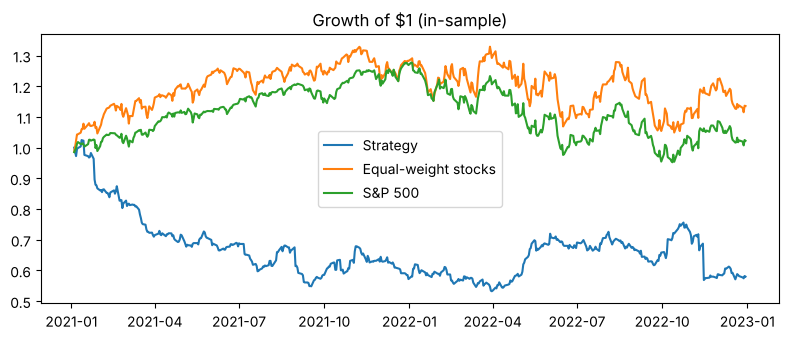


out-of-sample:
                       cumulative_return  annualised_return  sharpe  max_drawdown  sortino  win_rate  days_invested
Strategy (with costs)             -0.098             -0.099  -0.342        -0.201   -0.507     0.471          0.908
Strategy (no costs)                0.131              0.132   0.656        -0.126    0.973     0.507          0.908
Equal-weight stocks                0.162              0.164   0.943        -0.178    1.689     0.556          1.000
S&P 500                            0.242              0.244   1.736        -0.103    2.848     0.548          1.000


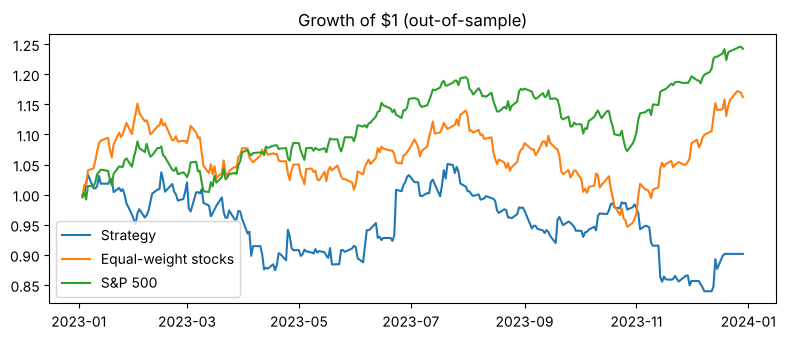

In [9]:
for period in ("in_sample", "out_of_sample"):
    table = pd.DataFrame(main[period]["metrics"]).T
    table.to_csv(OUT_DIR / f"table_{period}.csv")
    print(f"\n{period.replace('_', '-')}:")
    print(table.round(3).to_string())

    plt.figure(figsize=(8, 3.5))
    for name in ("Strategy (with costs)", "Equal-weight stocks", "S&P 500"):
        plt.plot((1 + main[period]["series"][name]).cumprod(), label=name.replace(" (with costs)", ""))
    plt.title(f"Growth of $1 ({period.replace('_', '-')})")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"fig_growth_{period}.png", dpi=150)
    plt.show()

## 8. Sanity Checks

### 8a. Look-ahead bias

This traces the first in-sample trade and checks that everything it uses is dated before the trade.

In [10]:
def lookahead_trace(sig, news, cal, win):
    lo = period_bounds(cal, win)["in_sample"][0]
    s = sig[sig["event_idx"] >= lo].sort_values("event_idx").iloc[0]
    t = int(s["event_idx"])
    arts = news[(news["ticker"] == s["ticker"]) & (news["event_idx"] == t)].sort_values("ts_utc")
    info = {"ticker": s["ticker"], "direction": "long" if s["direction"] > 0 else "short",
            "first_article_utc": str(arts["ts_utc"].iloc[0]), "last_article_utc": str(arts["ts_utc"].iloc[-1]),
            "beta_window_ends": str(cal[t - 1].date()), "event_day": str(cal[t].date()),
            "entry_close": str(cal[t + TRADE_DAYS[0] - 1].date()), "first_holding_day": str(cal[t + TRADE_DAYS[0]].date()),
            "last_holding_day": str(cal[t + TRADE_DAYS[-1]].date())}
    assert cal[t - 1] < cal[t] <= cal[t + TRADE_DAYS[0] - 1] < cal[t + TRADE_DAYS[0]]
    return info


trace = lookahead_trace(main_signals, news, calendar, window)
for k, v in trace.items():
    print(f"{k:>20}: {v}")
print("PASS: the beta window ends before the event day, the entry is after it, and returns are earned after entry")
results["lookahead_trace"] = trace

              ticker: ABBV
           direction: long
   first_article_utc: 2021-01-01 00:00:00+00:00
    last_article_utc: 2021-01-04 00:00:00+00:00
    beta_window_ends: 2020-12-31
           event_day: 2021-01-04
         entry_close: 2021-01-04
   first_holding_day: 2021-01-05
    last_holding_day: 2021-01-05
PASS: the beta window ends before the event day, the entry is after it, and returns are earned after entry


### 8b. Is there a lag?

This is the event-study profile from section 5: if sentiment is traded after the market has already reacted, the later bars will be near zero.

### 8c. Threshold and model sensitivity

This reruns the strategy at thresholds of 0.3 and 0.7 (with FinBERT), and with VADER at 0.5, to check the result does not depend on the one threshold chosen in advance. These are all reported whatever they show.

In [11]:
sens_rows, results["sensitivity"] = [], {}
for score, thr in [("finbert", t) for t in THRESHOLD_SENSITIVITY] + [("vader", THRESHOLD)]:
    o, _ = run_all(events, returns, mkt_returns, calendar, window, score, thr)
    results["sensitivity"][f"{score}_{thr}"] = {p: {"net": v["metrics"]["Strategy (with costs)"],
                                                    "gross": v["metrics"]["Strategy (no costs)"],
                                                    "n_trades": v["n_trades"]} for p, v in o.items()}
    for p in o:
        m_ = o[p]["metrics"]["Strategy (with costs)"]
        sens_rows.append({"model": score, "threshold": thr, "period": p, "trades": o[p]["n_trades"],
                          "cumulative": m_["cumulative_return"], "sharpe": m_["sharpe"], "max_drawdown": m_["max_drawdown"]})
for p in main:
    m_ = main[p]["metrics"]["Strategy (with costs)"]
    sens_rows.append({"model": "finbert", "threshold": THRESHOLD, "period": p, "trades": main[p]["n_trades"],
                      "cumulative": m_["cumulative_return"], "sharpe": m_["sharpe"], "max_drawdown": m_["max_drawdown"]})
sens = pd.DataFrame(sens_rows).sort_values(["model", "threshold", "period"])
sens.to_csv(OUT_DIR / "table_sensitivity.csv", index=False)
print(sens.round(3).to_string(index=False))

  model  threshold        period  trades  cumulative  sharpe  max_drawdown
finbert        0.3     in_sample    4628      -0.326  -0.954        -0.376
finbert        0.3 out_of_sample    2175      -0.044  -0.169        -0.191
finbert        0.5     in_sample    1979      -0.420  -0.805        -0.481
finbert        0.5 out_of_sample     861      -0.098  -0.342        -0.201
finbert        0.7     in_sample     992      -0.423  -0.588        -0.521
finbert        0.7 out_of_sample     384      -0.333  -1.153        -0.440
  vader        0.5     in_sample    1964      -0.588  -1.127        -0.619
  vader        0.5 out_of_sample    1131      -0.000   0.127        -0.304


## 9. Efficiency Measurement

This times the steps of the pipeline. The data pipeline's own log (how many unique headlines were scored and how fast) comes from `data_pipeline.py`. The cost of scoring grows linearly with the number of unique headlines, so it is the slow step; everything after it is vectorised.

In [12]:
t0 = time.perf_counter()
_ = run_all(events, returns, mkt_returns, calendar, window, "finbert", THRESHOLD)
timings["one_full_backtest_run"] = time.perf_counter() - t0
results["timings_seconds"] = {k: round(v, 3) for k, v in timings.items()}
for k, v in timings.items():
    print(f"{k:>24}: {v:.2f} s")

log_file = DATA_DIR / "pipeline_log.json"
if log_file.exists():
    plog = json.load(open(log_file))
    results["pipeline_log"] = plog
    print("\nData pipeline log:")
    print(json.dumps(plog, indent=2))
print(f"\n{len(events):,} stock-days -> {len(events) / max(sum(timings.values()), 1e-9):,.0f} stock-days per second end to end")

     align_and_aggregate: 0.04 s
        abnormal_returns: 0.07 s
                backtest: 0.04 s
   one_full_backtest_run: 0.04 s

Data pipeline log:
{
  "raw_rows": 69529,
  "columns_used": {
    "ts": "Date",
    "title": "Article_title",
    "ticker": "Stock_symbol",
    "summary": "Lsa_summary"
  },
  "universe_rows_deduped": 37430,
  "roundups_removed": 0,
  "articles_in_window": 28078,
  "tickers_with_news": 50,
  "tickers_total": 50,
  "unique_headlines": 24336,
  "scoring": {
    "finbert_headlines": {
      "device": "mps",
      "texts": 24336,
      "seconds": 28.6,
      "texts_per_second": 852.4
    },
    "finbert_summaries": {
      "device": "mps",
      "texts": 26293,
      "seconds": 142.7,
      "texts_per_second": 184.2
    },
    "articles_with_summary_averaged": 28078,
    "headline_only_mode": false
  },
  "total_seconds": 197.8
}

15,593 stock-days -> 84,781 stock-days per second end to end


## 10. Risk Measurement

This looks at where the strategy's risk comes from: how concentrated the trades are in a few stocks, how many positions are open at once, and the best and worst days.

In [13]:
risk = {}
for period, (lo, hi) in period_bounds(calendar, window).items():
    s = main_signals[(main_signals["event_idx"] >= lo) & (main_signals["event_idx"] + TRADE_LAST <= hi)]
    top5 = s["ticker"].value_counts().head(5)
    open_n = open_trades(main_signals, calendar, lo, hi)
    r = main[period]["series"]["Strategy (with costs)"]
    risk[period] = {"top5_tickers": top5.to_dict(), "top5_share_of_trades": float(top5.sum() / max(len(s), 1)),
                    "max_open_trades": int(open_n.max()),
                    "median_open_trades_when_invested": float(open_n[open_n > 0].median()) if (open_n > 0).any() else 0.0,
                    "worst_day": float(r.min()), "best_day": float(r.max()),
                    "long_share": float((s["direction"] > 0).mean()) if len(s) else float("nan")}
    print(period, json.dumps(risk[period], indent=1))
results["risk"] = risk

in_sample {
 "top5_tickers": {
  "COP": 81,
  "ABBV": 79,
  "CSL": 74,
  "BYND": 67,
  "CGC": 65
 },
 "top5_share_of_trades": 0.18494188984335522,
 "max_open_trades": 12,
 "median_open_trades_when_invested": 4.0,
 "worst_day": -0.172528096997761,
 "best_day": 0.07199898997237508,
 "long_share": 0.6478019201616978
}
out_of_sample {
 "top5_tickers": {
  "MANU": 33,
  "UBS": 30,
  "VIV": 30,
  "TSN": 25,
  "BYND": 24
 },
 "top5_share_of_trades": 0.16492450638792103,
 "max_open_trades": 13,
 "median_open_trades_when_invested": 3.0,
 "worst_day": -0.0577674087790128,
 "best_day": 0.08161744515711983,
 "long_share": 0.5609756097560976
}


## 11. Decision Rule

The rule was fixed in `PARAMETERS.md` before any results existed. The hypothesis counts as supported only if (1) the in-sample abnormal return on the day the strategy earns (day 1 for Strategy B) rises with FinBERT sentiment, positive and significant at 5%, AND (2) the out-of-sample strategy beats the equal-weight benchmark on Sharpe ratio after costs. Anything else is a "not supported".

In [14]:
c1 = results["event_study"]["finbert_in_sample"]["car_trade"]
oos = results["main"]["out_of_sample"]["metrics"]
cond1 = bool(c1["p"] == c1["p"] and c1["coef"] > 0 and c1["p"] < 0.05)
cond2 = bool(oos["Strategy (with costs)"]["sharpe"] > oos["Equal-weight stocks"]["sharpe"])
results["decision_rule"] = {"cond1_in_sample_car_positive_significant": cond1,
                            "cond2_oos_net_sharpe_beats_equal_weight": cond2,
                            "hypothesis_supported": bool(cond1 and cond2)}
print(f"1. In-sample trade-day coefficient: {c1['coef']:.1f} bps per unit score (p = {c1['p']:.3f})  -> {'met' if cond1 else 'NOT met'}")
print(f"2. Out-of-sample net Sharpe {oos['Strategy (with costs)']['sharpe']:.3f} vs equal-weight "
      f"{oos['Equal-weight stocks']['sharpe']:.3f}  -> {'met' if cond2 else 'NOT met'}")
print("HYPOTHESIS SUPPORTED" if cond1 and cond2 else "HYPOTHESIS NOT SUPPORTED")

1. In-sample trade-day coefficient: 9.7 bps per unit score (p = 0.302)  -> NOT met
2. Out-of-sample net Sharpe -0.342 vs equal-weight 0.943  -> NOT met
HYPOTHESIS NOT SUPPORTED


## 12. Pipeline Validation on Simulated Data

Before trusting any result, this checks the machinery on data where the truth is known. In one simulated world a response to sentiment is planted on the days the strategy earns (the true coefficient is 60 bps per unit score); in the other nothing is planted. The pipeline should find the effect in the first and nothing in the second. It also checks the timestamp rules on hand-made cases.

In [15]:
def check_alignment_rules():
    cal = pd.bdate_range("2023-03-01", "2023-03-31")
    def one(ts):
        df = pd.DataFrame({"ticker": ["A"], "ts_utc": pd.to_datetime([ts], utc=True), "title": "x"})
        return str(cal[assign_event_days(df, cal)["event_idx"].iloc[0]].date())
    assert one("2023-03-15 14:00:00") == "2023-03-15"     # 10:00 NY, before close
    assert one("2023-03-15 21:30:00") == "2023-03-16"     # 17:30 NY, after close
    assert one("2023-03-18 12:00:00") == "2023-03-20"     # Saturday
    assert one("2023-03-17 21:30:00") == "2023-03-20"     # Friday after close
    d = pd.DataFrame({"ticker": ["A", "A"], "ts_utc": pd.to_datetime(["2023-03-15", "2023-03-17"], utc=True), "title": "x"})
    o = assign_event_days(d, cal)
    want = ["2023-03-15", "2023-03-17"] if SAME_DAY_FOR_DATES else ["2023-03-16", "2023-03-20"]
    assert o.attrs["date_only"] and [str(cal[i].date()) for i in o["event_idx"]] == want


def simulate_world(kappa, seed, tks):
    """Random prices and news; kappa * score is added to returns on the trade days after each stock-day."""
    rng = np.random.default_rng(seed)
    cal = pd.bdate_range("2019-01-02", "2024-06-28")
    T, N = len(cal), len(tks)
    m = rng.normal(0.0004, 0.010, T)
    ret = m[:, None] * rng.uniform(0.8, 1.6, N)[None, :] + rng.normal(0, 0.015, (T, N))
    rows = []
    for tk in tks:
        n = 900
        ts = pd.to_datetime(rng.choice(pd.date_range("2021-01-01", "2023-12-28"), n)) + pd.to_timedelta(rng.integers(0, 86400, n), unit="s")
        fb = np.clip(rng.normal(0, 0.55, n), -1, 1)
        rows.append(pd.DataFrame({"ticker": tk, "ts_utc": ts.tz_localize("UTC"), "title": "x", "finbert": fb,
                                  "vader": np.clip(0.6 * fb + rng.normal(0, 0.3, n), -1, 1)}))
    nw = assign_event_days(pd.concat(rows, ignore_index=True), cal)
    ev = stock_day_scores(nw, tks)
    for off in TRADE_DAYS:
        t = ev["event_idx"].to_numpy() + off
        ok = t < T
        np.add.at(ret, (t[ok], ev["col"].to_numpy()[ok]), kappa * ev["finbert"].to_numpy()[ok])
    px = pd.DataFrame(100 * np.cumprod(1 + ret, axis=0), index=cal, columns=tks)
    mk = pd.Series(2500 * np.cumprod(1 + m), index=cal)
    win = {"start": pd.Timestamp("2021-01-01"), "end": pd.Timestamp("2023-12-31"),
           "holdout_start": pd.Timestamp("2023-01-01"), "in_sample_end": pd.Timestamp("2022-12-31")}
    return px, mk, nw, win


def analyse_world(px, mk, nw, win):
    cal = px.index
    R, M, B = returns_and_betas(px, mk)
    ev = label_periods(add_abnormal_returns(stock_day_scores(nw, list(px.columns)), R, M, B), cal, win)
    out, _ = run_all(ev, R, M, cal, win, "finbert", THRESHOLD)
    return (cluster_ols(ev[ev["period"] == "in_sample"], "car_trade", "finbert"),
            cluster_ols(ev[ev["period"] == "in_sample"], "ar0", "finbert"),
            out["in_sample"]["metrics"]["Strategy (with costs)"]["sharpe"])


check_alignment_rules()
print("Timestamp alignment rules: PASS")
validation = {}
for name, kappa in (("planted effect", 0.006 / len(TRADE_DAYS)), ("no effect", 0.0)):
    car, ar0, sharpe = analyse_world(*simulate_world(kappa, 7, tickers))
    validation[name] = {"car_coef_bps": car["coef"], "car_p": car["p"], "day0_p": ar0["p"], "strategy_sharpe": sharpe}
    print(f"{name:>15}: trade-day coefficient {car['coef']:.1f} bps (p = {car['p']:.3g}), day-0 p = {ar0['p']:.2f}, net Sharpe {sharpe:.2f}")
assert 45 < validation["planted effect"]["car_coef_bps"] < 75 and validation["planted effect"]["car_p"] < 0.001
assert abs(validation["no effect"]["car_coef_bps"]) < 25 and validation["no effect"]["car_p"] > 0.01
assert validation["planted effect"]["strategy_sharpe"] > 1.0 and validation["no effect"]["strategy_sharpe"] < 0.8
print("VALIDATION PASSED: the pipeline recovers a planted effect (true value 60 bps) and finds nothing when there is none")
results["validation"] = validation

Timestamp alignment rules: PASS


 planted effect: trade-day coefficient 61.3 bps (p = 4.08e-149), day-0 p = 0.81, net Sharpe 7.83


      no effect: trade-day coefficient 1.3 bps (p = 0.589), day-0 p = 0.83, net Sharpe -2.36
VALIDATION PASSED: the pipeline recovers a planted effect (true value 60 bps) and finds nothing when there is none


## 13. Save Results

Everything above is saved to one file, which the report is written from.

In [16]:
def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else float(o)
    if isinstance(o, np.integer):
        return int(o)
    return o


json.dump(clean(results), open(OUT_DIR / "results.json", "w"), indent=2)
print("Saved", OUT_DIR / "results.json")

Saved outputs/results.json
